In [1]:
import pandas as pd

train_df = pd.read_csv(
    r"C:\Users\ASUS\Desktop\mobile-review-sentiment-analysis\data\processed\train.csv"
)

validation_df = pd.read_csv(
    r"C:\Users\ASUS\Desktop\mobile-review-sentiment-analysis\data\processed\validation.csv"
)

test_df = pd.read_csv(
    r"C:\Users\ASUS\Desktop\mobile-review-sentiment-analysis\data\processed\test.csv"
)

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train = vectorizer.fit_transform(
    train_df["clean_text"]
)

X_validation = vectorizer.transform(
    validation_df["clean_text"]
)

X_test = vectorizer.transform(
    test_df["clean_text"]
)

y_train = train_df["sentiment"]

y_validation = validation_df["sentiment"]

y_test = test_df["sentiment"]

print("Train shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Test shape:", X_test.shape)

Train shape: (15988, 10000)
Validation shape: (1998, 10000)
Test shape: (1999, 10000)


In [3]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000
)

model.fit(
    X_train,
    y_train
)

print("Training completed!")

Training completed!


In [4]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

validation_predictions = model.predict(
    X_validation
)

accuracy = accuracy_score(
    y_validation,
    validation_predictions
)

print("Validation Accuracy:", accuracy)

print(
    classification_report(
        y_validation,
        validation_predictions
    )
)

Validation Accuracy: 0.8128128128128128
              precision    recall  f1-score   support

    Negative       0.76      0.60      0.67       335
     Neutral       0.54      0.13      0.21       229
    Positive       0.83      0.97      0.90      1434

    accuracy                           0.81      1998
   macro avg       0.71      0.57      0.59      1998
weighted avg       0.78      0.81      0.78      1998



In [5]:
test_predictions = model.predict(X_test)

accuracy = accuracy_score(
    y_test,
    test_predictions
)

print("Test Accuracy:", accuracy)

print(
    classification_report(
        y_test,
        test_predictions
    )
)

Test Accuracy: 0.8139069534767384
              precision    recall  f1-score   support

    Negative       0.79      0.57      0.67       336
     Neutral       0.51      0.13      0.20       229
    Positive       0.83      0.98      0.90      1434

    accuracy                           0.81      1999
   macro avg       0.71      0.56      0.59      1999
weighted avg       0.79      0.81      0.78      1999



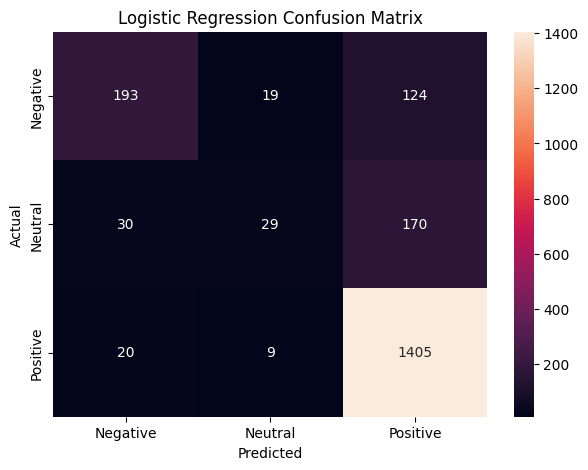

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[
        "Negative",
        "Neutral",
        "Positive"
    ]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Negative",
        "Neutral",
        "Positive"
    ],
    yticklabels=[
        "Negative",
        "Neutral",
        "Positive"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [7]:
import joblib

joblib.dump(
    vectorizer,
    "C:\\Users\\ASUS\\Desktop\\mobile-review-sentiment-analysis\\models\\tfidf_vectorizer.pkl"
)

joblib.dump(
    model,
    "C:\\Users\\ASUS\\Desktop\\mobile-review-sentiment-analysis\\models\\tfidf_logistic_regression.pkl"
)

print("TF-IDF model saved!")

TF-IDF model saved!
